In [87]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [88]:
df = pd.read_csv('Advertising.csv')

In [89]:
df.head()

,TV,radio,newspaper,sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


In [90]:
X = df.drop('sales', axis=1)

In [91]:
y = df['sales']

In [92]:
from sklearn.preprocessing import PolynomialFeatures

In [93]:
polynomial_converter = PolynomialFeatures(degree=2, include_bias=False)

In [94]:
polynomial_converter.fit(X)

,degree,2
,interaction_only,False
,include_bias,False
,order,'C'


In [95]:
polynomial_converter.transform(X).shape

(200, 9)

In [96]:
poly_features = polynomial_converter.transform(X)

In [97]:
X.shape

(200, 3)

In [118]:
X.iloc[0]

TV           230.1
radio         37.8
newspaper     69.2
Name: 0, dtype: float64

In [161]:
poly_features[0]

array([2.30100000e+02, 3.78000000e+01, 6.92000000e+01, 5.29460100e+04,
       8.69778000e+03, 1.59229200e+04, 1.42884000e+03, 2.61576000e+03,
       4.78864000e+03, 1.21828769e+07, 2.00135918e+06, 3.66386389e+06,
       3.28776084e+05, 6.01886376e+05, 1.10186606e+06, 5.40101520e+04,
       9.88757280e+04, 1.81010592e+05, 3.31373888e+05, 2.80327997e+09,
       4.60512747e+08, 8.43055082e+08, 7.56513769e+07, 1.38494055e+08,
       2.53539381e+08, 1.24277360e+07, 2.27513050e+07, 4.16505372e+07,
       7.62491316e+07, 2.04158375e+06, 3.73750252e+06, 6.84220038e+06,
       1.25259330e+07, 2.29310730e+07, 6.45034722e+11, 1.05963983e+11,
       1.93986974e+11, 1.74073818e+10, 3.18674821e+10, 5.83394116e+10,
       2.85962205e+09, 5.23507528e+09, 9.58378861e+09, 1.75449252e+10,
       4.69768420e+08, 8.59999329e+08, 1.57439031e+09, 2.88221718e+09,
       5.27643991e+09, 7.71718656e+07, 1.41277595e+08, 2.58635174e+08,
       4.73480266e+08, 8.66794561e+08, 1.58683026e+09, 1.48422490e+14,
      

In [120]:
from sklearn.model_selection import train_test_split

In [121]:
X_train, X_test, y_train, y_test = train_test_split(poly_features, y, test_size=0.3, random_state=42)

In [122]:
from sklearn.linear_model import LinearRegression

In [123]:
model = LinearRegression()

In [124]:
model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [125]:
test_predictions = model.predict(X_test)

In [126]:
model.coef_

array([ 5.35865479e-14,  1.23110410e-13, -2.06346273e-14, -1.36917416e-14,
       -7.41147060e-15, -4.18416398e-15,  7.49413035e-16, -4.74911177e-15,
       -3.25940130e-15,  3.86838137e-14,  9.66941048e-15,  4.37931527e-15,
        2.65498106e-15,  4.48461767e-15,  9.81071676e-16,  1.03616540e-15,
        1.24630990e-15, -3.06548748e-16, -1.70274312e-16,  2.45639738e-12,
        4.05784020e-13,  1.44149296e-13,  1.38398370e-13,  9.12319253e-14,
        1.34411540e-13,  7.16979433e-14,  4.50052428e-14,  4.68619157e-14,
        6.17442026e-14,  3.68813406e-14,  2.56905899e-14,  2.26444089e-14,
        2.12549193e-14,  1.14320026e-14,  9.15684368e-11,  1.31511973e-11,
        3.24305975e-12,  4.15981288e-12,  3.51955480e-12,  8.18699796e-12,
        2.50631376e-12,  1.42573947e-12,  2.12220541e-12,  4.12507214e-12,
        1.43895796e-12,  8.38133823e-13,  8.18122811e-13,  9.80097605e-13,
        1.45683484e-12,  7.56102167e-13,  5.06797470e-13,  4.44585562e-13,
        4.45428487e-13,  

In [127]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [128]:
MAE = mean_absolute_error(y_test, test_predictions)

In [129]:
MSE = mean_squared_error(y_test, test_predictions)

In [130]:
RMSE = np.sqrt(MSE)

In [131]:
MAE

1381.663655543791

In [132]:
RMSE

np.float64(10191.095826425759)

In [133]:
model.coef_

array([ 5.35865479e-14,  1.23110410e-13, -2.06346273e-14, -1.36917416e-14,
       -7.41147060e-15, -4.18416398e-15,  7.49413035e-16, -4.74911177e-15,
       -3.25940130e-15,  3.86838137e-14,  9.66941048e-15,  4.37931527e-15,
        2.65498106e-15,  4.48461767e-15,  9.81071676e-16,  1.03616540e-15,
        1.24630990e-15, -3.06548748e-16, -1.70274312e-16,  2.45639738e-12,
        4.05784020e-13,  1.44149296e-13,  1.38398370e-13,  9.12319253e-14,
        1.34411540e-13,  7.16979433e-14,  4.50052428e-14,  4.68619157e-14,
        6.17442026e-14,  3.68813406e-14,  2.56905899e-14,  2.26444089e-14,
        2.12549193e-14,  1.14320026e-14,  9.15684368e-11,  1.31511973e-11,
        3.24305975e-12,  4.15981288e-12,  3.51955480e-12,  8.18699796e-12,
        2.50631376e-12,  1.42573947e-12,  2.12220541e-12,  4.12507214e-12,
        1.43895796e-12,  8.38133823e-13,  8.18122811e-13,  9.80097605e-13,
        1.45683484e-12,  7.56102167e-13,  5.06797470e-13,  4.44585562e-13,
        4.45428487e-13,  

In [134]:
# Создать различные степени полинома
# Разбить данные на тестовый и обучающий набор данных
# Обучить модель
# Сохранить метрики в RMSE для обучающего и тестового набора данных
# Нарисовать график с результатами - ошибка и степенями полиномы

In [137]:
train_rmse_errors = []
test_rmse_errors = []

for d in range(1,10):
    polynomial_converter = PolynomialFeatures(degree=d, include_bias=False)
    poly_features = polynomial_converter.fit_transform(X)
    
    X_train, X_test, y_train, y_test = train_test_split(poly_features, y, test_size=0.3, random_state=42)
    
    model = LinearRegression()
    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    train_rmse = np.sqrt(mean_squared_error(y_train, train_pred))
    test_rmse = np.sqrt(mean_squared_error(y_test, test_pred))

    train_rmse_errors.append(train_rmse)
    test_rmse_errors.append(test_rmse)

In [138]:
train_rmse_errors

[np.float64(1.5745968305905442),
 np.float64(0.5950712355838926),
 np.float64(0.46887581118220906),
 np.float64(0.36946897017714747),
 np.float64(0.2438220623995386),
 np.float64(0.22508530955094164),
 np.float64(0.23124892679113013),
 np.float64(0.2790197877326791),
 np.float64(0.5933678496074968)]

In [139]:
test_rmse_errors

[np.float64(1.9485372043446394),
 np.float64(0.7233218473857609),
 np.float64(0.5392350985677339),
 np.float64(1.3032266057078963),
 np.float64(5.946749503226517),
 np.float64(22.044015020858332),
 np.float64(235.30585224731595),
 np.float64(5089.676161403181),
 np.float64(10191.095826425759)]

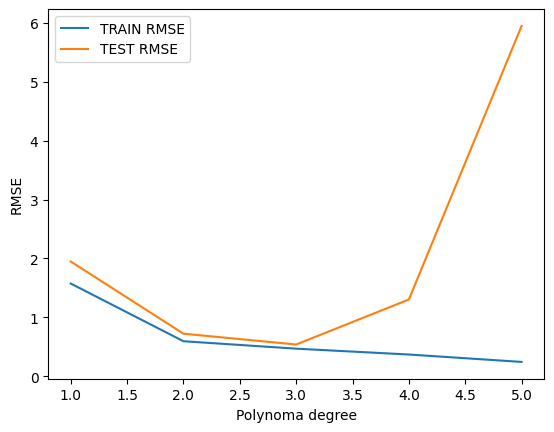

In [142]:
plt.plot(range(1,6), train_rmse_errors[:5], label='TRAIN RMSE')
plt.plot(range(1,6), test_rmse_errors[:5], label='TEST RMSE')
plt.xlabel('Polynoma degree')
plt.ylabel('RMSE')
plt.legend()

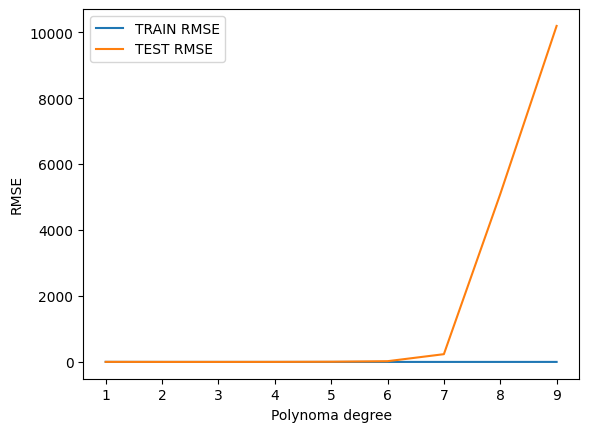

In [144]:
plt.plot(range(1,10), train_rmse_errors, label='TRAIN RMSE')
plt.plot(range(1,10), test_rmse_errors, label='TEST RMSE')
plt.xlabel('Polynoma degree')
plt.ylabel('RMSE')
plt.legend()

In [145]:
final_poly_converter = PolynomialFeatures(degree=3, include_bias=False)
final_model = LinearRegression()

In [147]:
full_converted_x = final_poly_converter.fit_transform(X)
final_model.fit(full_converted_x, y)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [148]:
from joblib import dump, load

In [149]:
dump(final_model, 'final_poly_model.joblib')

['final_poly_model.joblib']

In [151]:
dump(final_poly_converter, 'final_converter.joblib')

['final_converter.joblib']

In [152]:
loaded_converter = load('final_converter.joblib')

In [153]:
loaded_model = load('final_poly_model.joblib')

In [154]:
campaign = [[149,22,12]]

In [155]:
loaded_converter.transform(campaign)

/home/rustam/Desktop/projects/AI_course/venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


array([[1.490000e+02, 2.200000e+01, 1.200000e+01, 2.220100e+04,
        3.278000e+03, 1.788000e+03, 4.840000e+02, 2.640000e+02,
        1.440000e+02, 3.307949e+06, 4.884220e+05, 2.664120e+05,
        7.211600e+04, 3.933600e+04, 2.145600e+04, 1.064800e+04,
        5.808000e+03, 3.168000e+03, 1.728000e+03]])

In [156]:
loaded_converter.transform(campaign).shape

/home/rustam/Desktop/projects/AI_course/venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


(1, 19)

In [157]:
transformed_data = loaded_converter.transform(campaign)

/home/rustam/Desktop/projects/AI_course/venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


In [158]:
loaded_model.predict(transformed_data)

array([14.64501014])